# 2회차 스터디
 - 1회차 복습
   - EDA, 시각화
   - 지도학습

In [45]:
# 기존 라이브러리 - 복붙하세요. ctrl + c, ctrl + v
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 폰트 설정: Windows
# plt.rcParams['font.family'] = 'AppleSDGothicNeo'   # 한글 폰트 설정: Mac
plt.rcParams['axes.unicode_minus'] = False      # 마이너스 기호 깨짐 방지

# 복습

In [46]:
# 데이터 불러오기
df = pd.read_csv('iris.csv')
df


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [47]:
# 데이터프레임 확인
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [48]:
# 데이터프레임 기본적 기술통계
df.describe()

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


<Axes: xlabel='sepal_length', ylabel='Count'>

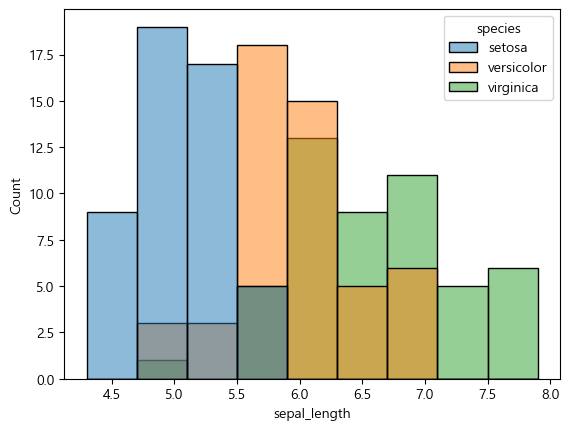

In [49]:
sns.histplot(data=df, x='sepal_length', hue='species')

<Axes: >

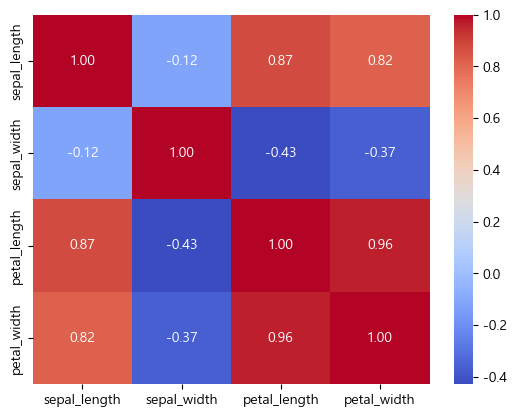

In [50]:
corr = df.iloc[:, :-1].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')

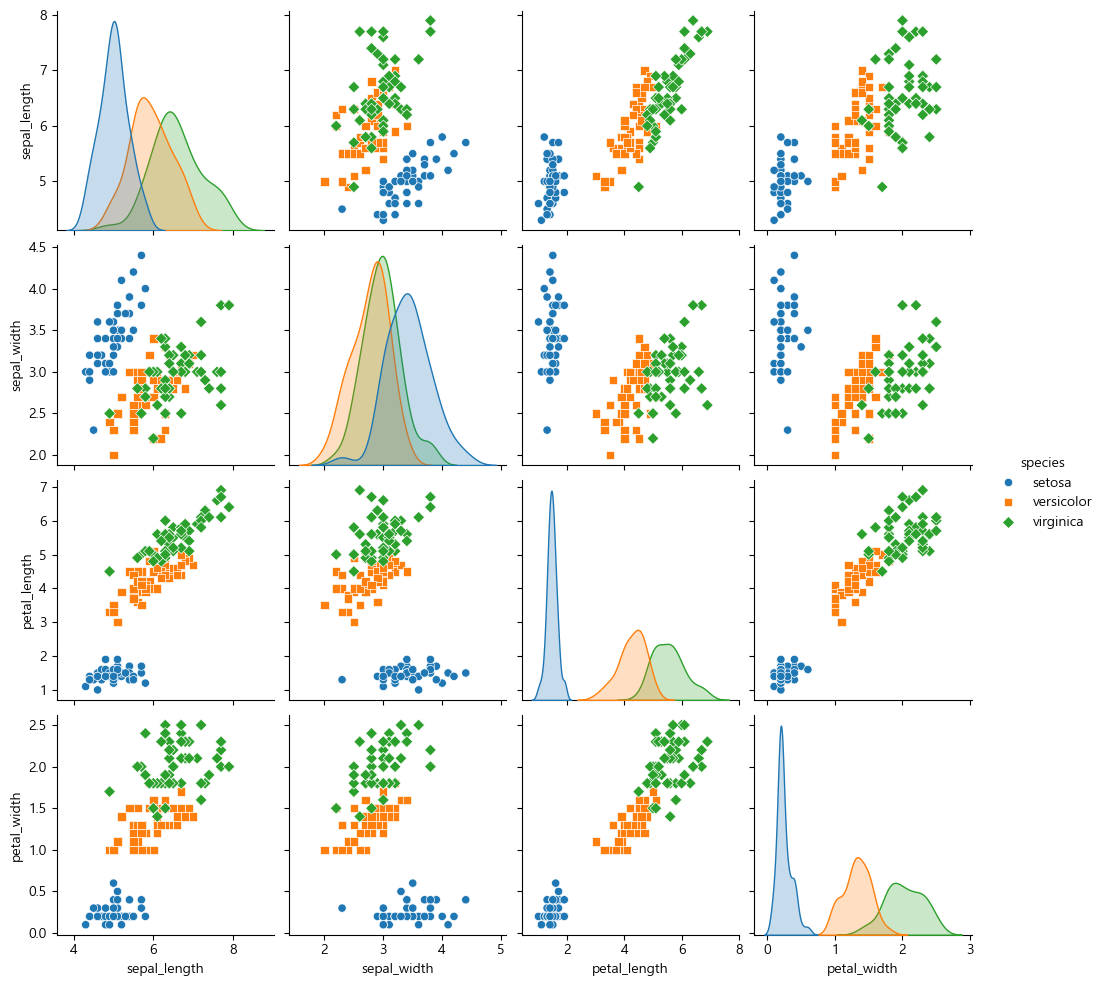

In [51]:
sns.pairplot(df, hue='species', markers=['o', 's', 'D'])

# 머신러닝
 - 딥러닝 vs 머신러닝
 - 지도학습 vs 비지도학습
 - 학습 알고리즘(모델)
 - 하이퍼 파라메터  vs (그냥)파라메터
 - 데이터와 라벨

In [52]:
# 모델 훈련을 위한 데이터 준비
from sklearn.model_selection import train_test_split

# 피처와 라벨 분리
X = df.drop(columns = 'species')   # 피처         - 설명변수, 독립변수  (꽃잎 길이, 꽃잎 너비, 꽃받침 길이, 꽃받침 너비)
y = df['species']                  # 라벨, 타겟    - 목표변수, 종속변수  (종)

# 데이터셋 분리
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)


In [53]:
# 어떻게 나뉘었는지 확인
X_train.shape, X_test.shape, y_train.shape, y_test.shape


((105, 4), (45, 4), (105,), (45,))

# 모델 학습

In [54]:
# 의사결정나무 decision tree 모델 학습
from sklearn.tree import DecisionTreeClassifier

# 모델 불러오기
model = DecisionTreeClassifier(random_state=42)  # 난수 시드 고정은 선택사항

# 모델 학습
model.fit(X_train, y_train)

# 예측
y_pred = model.predict(X_test)
y_pred


array(['virginica', 'versicolor', 'virginica', 'virginica', 'virginica',
       'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica',
       'setosa', 'setosa', 'virginica', 'virginica', 'setosa',
       'virginica', 'versicolor', 'setosa', 'setosa', 'setosa',
       'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica',
       'versicolor', 'versicolor', 'versicolor', 'versicolor', 'setosa',
       'virginica', 'virginica', 'virginica', 'setosa', 'virginica',
       'setosa', 'setosa', 'setosa', 'setosa', 'virginica', 'versicolor',
       'setosa', 'virginica', 'virginica', 'versicolor'], dtype=object)

In [55]:
# 모델 평가
## 정확도 계산 accuracy
acc = (y_pred == y_test).sum() / len(y_test)
print(f'정확도: {acc*100:.3f}%')


정확도: 93.333%


In [56]:
# 평가 라이브러리 활용하여 정확도 계산
from sklearn.metrics import accuracy_score
acc = accuracy_score(y_test, y_pred)
print(f'정확도: {acc*100:.3f}%')


정확도: 93.333%


In [57]:
# 어떤걸 틀렸을까?
result = X_test.copy()
result['y_test'] = y_test
result['y_pred'] = y_pred
result['정답'] = result['y_test'] == result['y_pred']
result[result['정답'] == False]

,sepal_length,sepal_width,petal_length,petal_width,y_test,y_pred,정답
56,6.3,3.3,4.7,1.6,versicolor,virginica,False
85,6.0,3.4,4.5,1.6,versicolor,virginica,False
77,6.7,3.0,5.0,1.7,versicolor,virginica,False


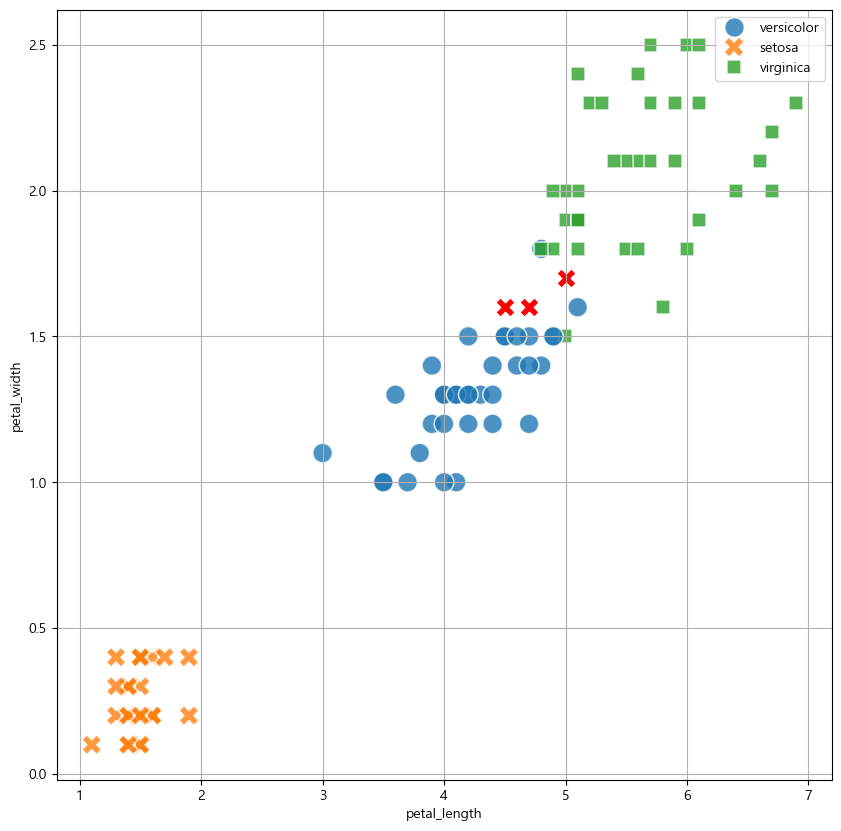

In [58]:
# 뭐가 틀렸는지 시각화
plt.figure(figsize=(10, 10))

sns.scatterplot(data=X_train, x='petal_length', y='petal_width', hue=y_train, alpha=0.8, style=y_train, s=200)
# sns.scatterplot(data=result, x='petal_length', y='petal_width', hue='y_test', style='y_test', s=200)
wrong = result[result['정답'] == False]
sns.scatterplot(data=wrong, x='petal_length', y='petal_width', marker='X', color='red', s=200)
plt.grid(True)

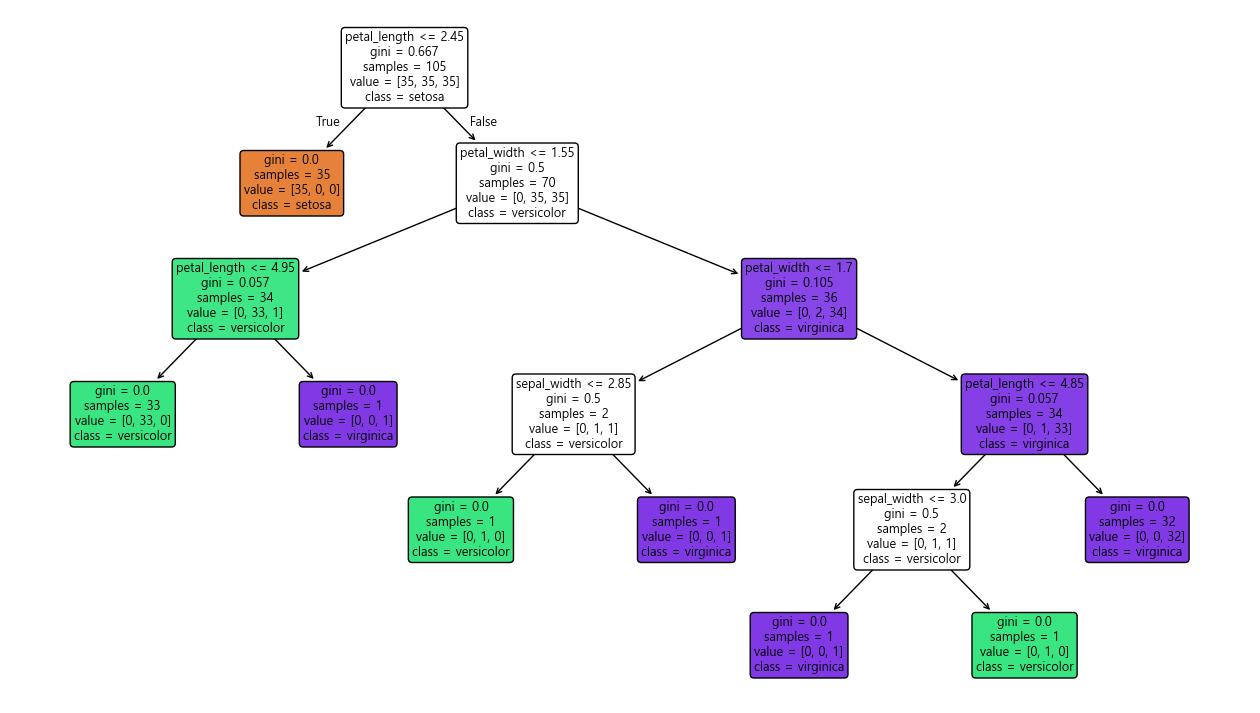

In [59]:
# 트리 그래프
from sklearn.tree import plot_tree
plt.figure(figsize=(16, 9))
_ = plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True, rounded=True, fontsize=9)

In [60]:
# 불순도 계산


- 트리 읽는 법
  - 노드 vs 엣지
  - 루트 노드
  - 리프 노드
  - 깊이
  - 분할
  - 지니 불순도
    - 1 - ((35/105)**2 + (35/105)**2 + (35/105)**2)

In [61]:
# 모델을 바꿔보자
from sklearn.tree import DecisionTreeClassifier

# 모델 불러오기
model = DecisionTreeClassifier(
    random_state=42,
    max_depth=3,
    min_samples_split=2,
    min_samples_leaf=1
)
# 모델 학습
model.fit(X_train, y_train)

# 예측
y_pred = model.predict(X_test)
y_pred


array(['virginica', 'versicolor', 'virginica', 'versicolor', 'virginica',
       'virginica', 'versicolor', 'versicolor', 'setosa', 'virginica',
       'setosa', 'setosa', 'virginica', 'virginica', 'setosa',
       'virginica', 'versicolor', 'setosa', 'setosa', 'setosa',
       'versicolor', 'setosa', 'versicolor', 'virginica', 'virginica',
       'versicolor', 'versicolor', 'versicolor', 'versicolor', 'setosa',
       'virginica', 'virginica', 'versicolor', 'setosa', 'virginica',
       'setosa', 'setosa', 'setosa', 'setosa', 'virginica', 'versicolor',
       'setosa', 'virginica', 'virginica', 'versicolor'], dtype=object)

In [62]:
# 모델 평가
## 정확도 계산 accuracy
acc = (y_pred == y_test).sum() / len(y_test)
print(f'정확도: {acc*100:.3f}%')


정확도: 97.778%


In [63]:
# 어떤걸 틀렸을까?
result = X_test.copy()
result['y_test'] = y_test
result['y_pred'] = y_pred
result['정답'] = result['y_test'] == result['y_pred']
result[result['정답'] == False]

,sepal_length,sepal_width,petal_length,petal_width,y_test,y_pred,정답
77,6.7,3.0,5.0,1.7,versicolor,virginica,False


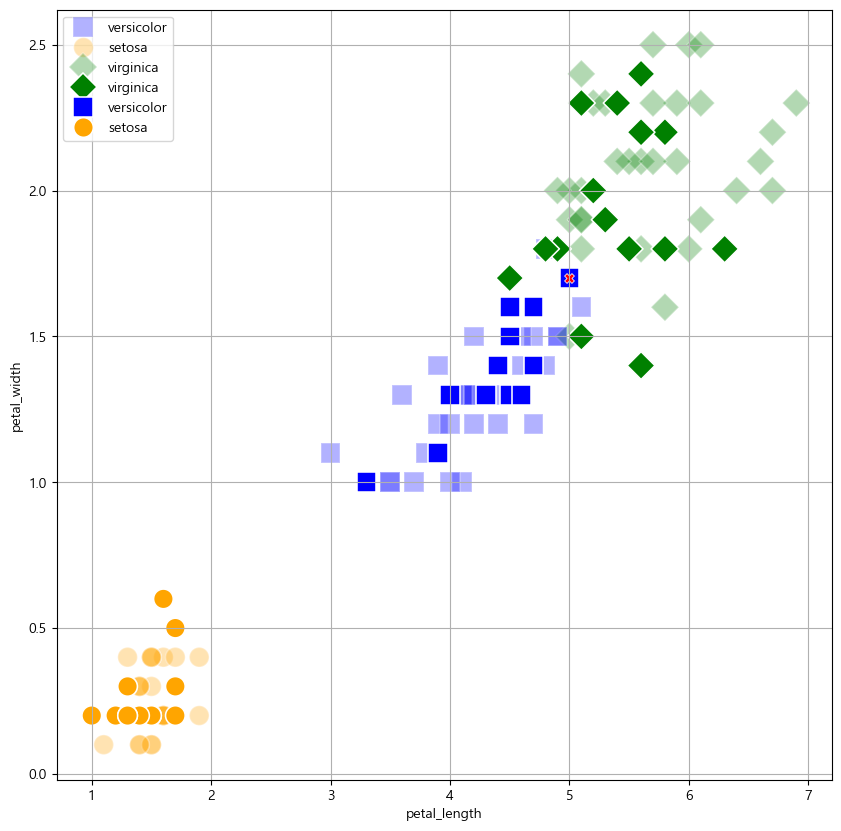

In [64]:
# 뭐가 틀렸는지 시각화
plt.figure(figsize=(10, 10))
colors = {
    'setosa': 'orange',
    'versicolor': 'blue',
    'virginica': 'green'
}
marker = {
    'setosa': 'o',
    'versicolor': 's',
    'virginica': 'D'
}
sns.scatterplot(data=X_train, x='petal_length', y='petal_width', hue=y_train, alpha=0.3, style=y_train, s=200, palette=colors, markers=marker)
sns.scatterplot(data=result , x='petal_length', y='petal_width', hue=y_test , alpha=1  , style=y_test , s=200, palette=colors, markers=marker)
wrong = result[result['정답'] == False]
sns.scatterplot(data=wrong, x='petal_length', y='petal_width', marker='X', color='red', s=50)
plt.grid(True)

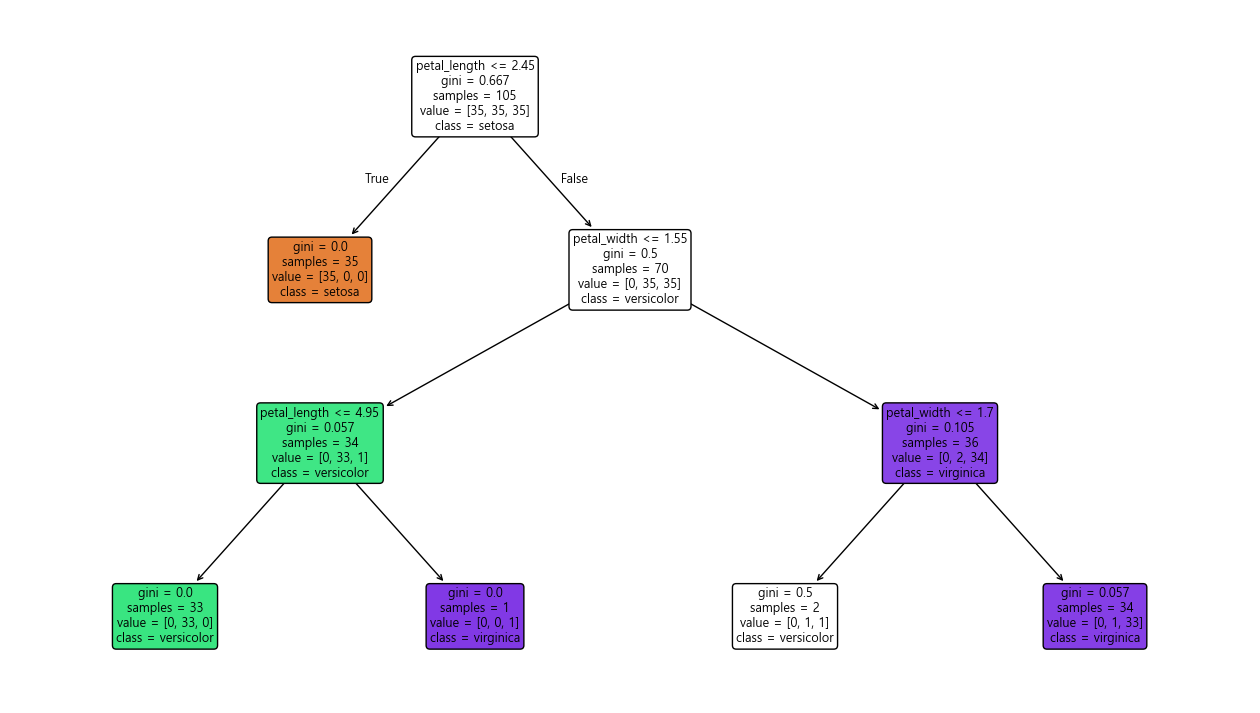

In [65]:
# 트리 그래프
from sklearn.tree import plot_tree
plt.figure(figsize=(16, 9))
_ = plot_tree(model, feature_names=X.columns, class_names=model.classes_, filled=True, rounded=True, fontsize=9)

※ 복잡한게 좋은 성능을 내는건 아니다.

# KNN 모델

In [66]:
# 데이터 전처리
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# StandardScaler를 사용하여 표준화
scaler = StandardScaler()
scaler.fit(X_train)  # 학습 데이터에 대해 fit 수행
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Q. test-set은 왜 transform만 하는가?
##   -> 데이터 누수(data leakage) 문제 발생
## 표준화는 언제 하는가?
##   -> 거리를 사용하는 알고리즘의 경우 표준화
##   -> 선형회귀, 로지스틱 회귀, SVM, KNN 등
##   -> 트리모델은 표준화 필요 낮음

In [67]:
# knn
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)


In [68]:
# 모델 평가
## 정확도 계산 accuracy
acc = (y_pred == y_test).sum() / len(y_test)
print(f'정확도: {acc*100:.3f}%')


정확도: 91.111%


In [69]:
# 어떤걸 틀렸을까?
result = X_test.copy()
result['y_test'] = y_test
result['y_pred'] = y_pred
result['정답'] = result['y_test'] == result['y_pred']
result[result['정답'] == False]

,sepal_length,sepal_width,petal_length,petal_width,y_test,y_pred,정답
133,6.3,2.8,5.1,1.5,virginica,versicolor,False
138,6.0,3.0,4.8,1.8,virginica,versicolor,False
134,6.1,2.6,5.6,1.4,virginica,versicolor,False
106,4.9,2.5,4.5,1.7,virginica,versicolor,False


In [70]:
# 어떤걸 틀렸을까?
result = X_test.copy()
result['y_test'] = y_test
result['y_pred'] = y_pred
result['정답'] = result['y_test'] == result['y_pred']
result[result['정답'] == False]

,sepal_length,sepal_width,petal_length,petal_width,y_test,y_pred,정답
133,6.3,2.8,5.1,1.5,virginica,versicolor,False
138,6.0,3.0,4.8,1.8,virginica,versicolor,False
134,6.1,2.6,5.6,1.4,virginica,versicolor,False
106,4.9,2.5,4.5,1.7,virginica,versicolor,False


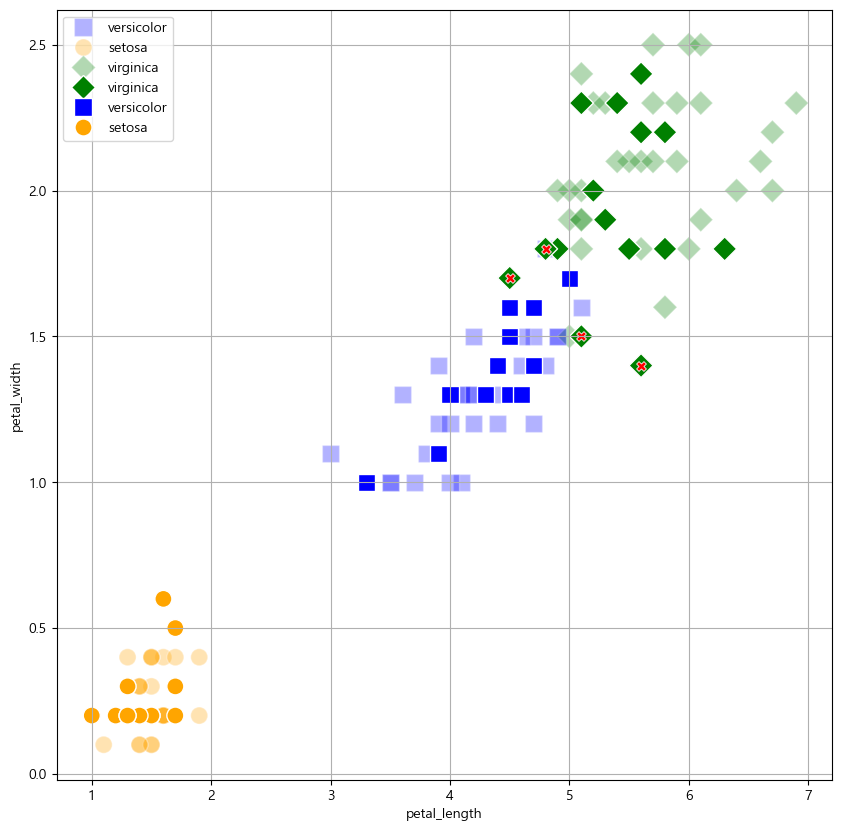

In [71]:
# 뭐가 틀렸는지 시각화
plt.figure(figsize=(10, 10))
colors = {
    'setosa': 'orange',
    'versicolor': 'blue',
    'virginica': 'green'
}
marker = {
    'setosa': 'o',
    'versicolor': 's',
    'virginica': 'D'
}
sns.scatterplot(data=X_train, x='petal_length', y='petal_width', hue=y_train, alpha=0.3, style=y_train, s=150, palette=colors, markers=marker)
sns.scatterplot(data=result , x='petal_length', y='petal_width', hue=y_test , alpha=1  , style=y_test , s=150, palette=colors, markers=marker)
wrong = result[result['정답'] == False]
sns.scatterplot(data=wrong, x='petal_length', y='petal_width', marker='X', color='red', s=50)
plt.grid(True)

In [72]:
# 데이터 전처리
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# StandardScaler를 사용하여 표준화
scaler = StandardScaler()
scaler.fit(X_train)  # 학습 데이터에 대해 fit 수행
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Q. test-set은 왜 transform만 하는가?
##   -> 데이터 누수(data leakage) 문제 발생
## 표준화는 언제 하는가?
##   -> 거리를 사용하는 알고리즘의 경우 표준화
##   -> 선형회귀, 로지스틱 회귀, SVM, KNN 등
##   -> 트리모델은 표준화 필요 낮음

In [73]:
# 스케일러 결과 확인
display(X_train.describe())
display(X_train.shape)

,sepal_length,sepal_width,petal_length,petal_width
count,105.000000,105.000000,105.000000,105.000000
mean,5.873333,3.055238,3.784762,1.205714
std,0.862941,0.457203,1.784052,0.777549
min,4.300000,2.000000,1.100000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.200000,1.300000
75%,6.400000,3.300000,5.100000,1.900000
max,7.900000,4.400000,6.900000,2.500000


(105, 4)

In [74]:
display(pd.DataFrame(X_train_scaled, columns=X_train.columns).describe().round(5))
display(X_train_scaled.shape)
# 민맥스 정규화와 차이를 비교해보자

,sepal_length,sepal_width,petal_length,petal_width
count,105.00000,105.00000,105.00000,105.00000
mean,0.00000,-0.00000,-0.00000,-0.00000
std,1.00480,1.00480,1.00480,1.00480
min,-1.83197,-2.31910,-1.51208,-1.42887
25%,-0.90046,-0.56094,-1.23048,-1.17042
50%,-0.08539,-0.12140,0.23387,0.12184
75%,0.61324,0.53791,0.74076,0.89720
max,2.35982,2.95539,1.75453,1.67255


(105, 4)

# 펭귄 데이터셋

In [75]:
df = pd.read_csv('penguins.csv')
display(df.shape)

(344, 7)

In [76]:
display(df)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE
...,...,...,...,...,...,...,...
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN
340,Gentoo,Biscoe,46.8,14.3,215.0,4850.0,FEMALE
341,Gentoo,Biscoe,50.4,15.7,222.0,5750.0,MALE
342,Gentoo,Biscoe,45.2,14.8,212.0,5200.0,FEMALE


In [82]:
df.describe(include='all')

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
count,344,344,342.000000,342.000000,342.000000,342.000000,333
unique,3,3,NaN,NaN,NaN,NaN,2
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,MALE
freq,152,168,NaN,NaN,NaN,NaN,168
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN


In [98]:
# 결측치 확인
df.isnull().sum() / len(df) * 100

species              0.000000
island               0.000000
bill_length_mm       0.581395
bill_depth_mm        0.581395
flipper_length_mm    0.581395
body_mass_g          0.581395
sex                  3.197674
dtype: float64

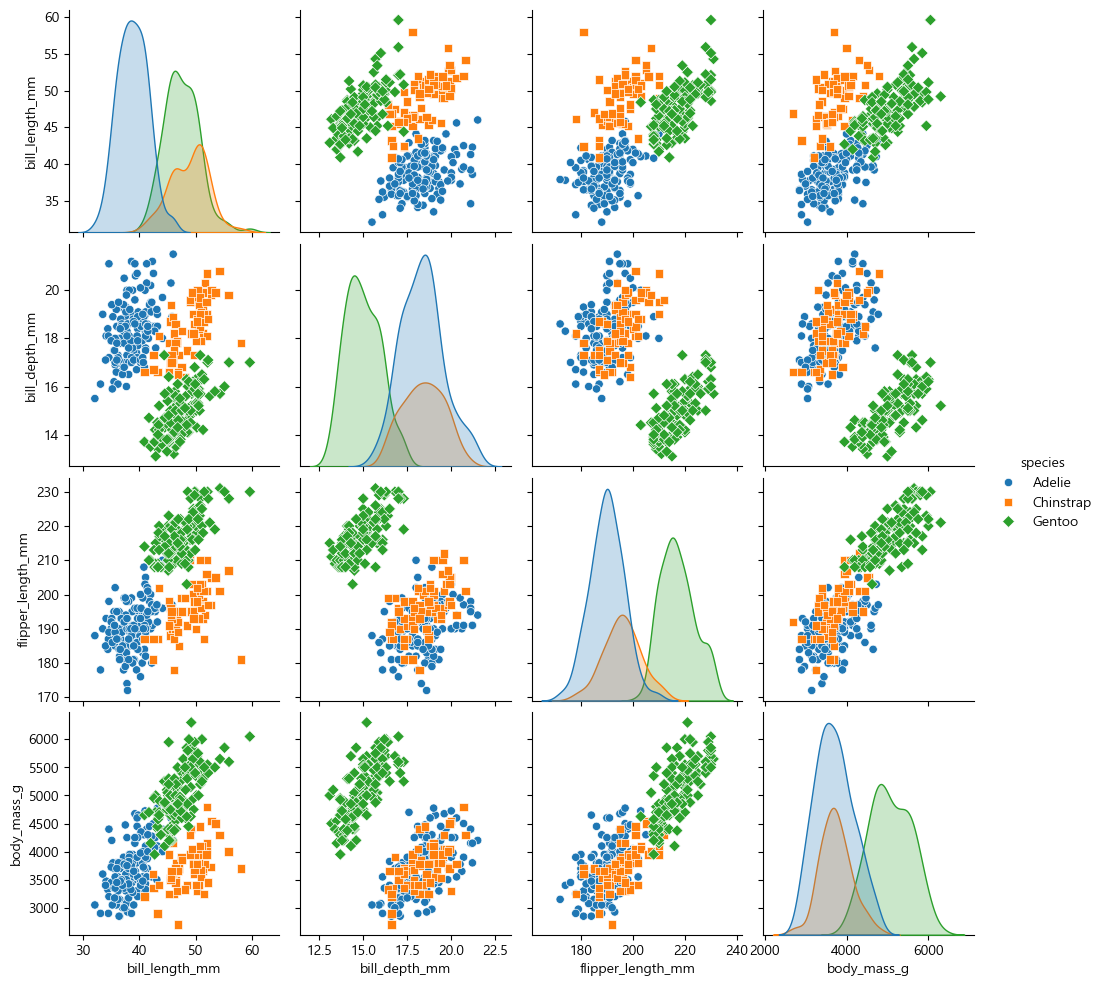

In [83]:
sns.pairplot(df, hue='species', markers=['o', 's', 'D'])

<Axes: >

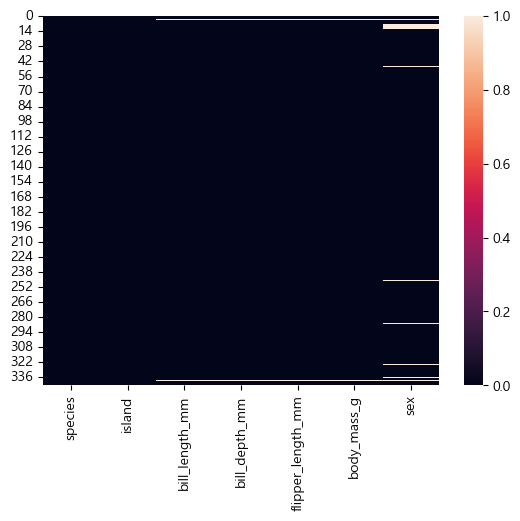

In [77]:
sns.heatmap(df.isnull())
# 결측이 있음

# 머신러닝 파이프라인

In [ ]:
from sklearn.model_selection import train_test_split

from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [ ]:
# 데이터 컬럼의 종류 구분
cat_cols = ['island', 'sex']
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
target_col = ['species']

In [120]:
# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(
    df[cat_cols + num_cols], df[target_col], 
    test_size=0.2, stratify=df[target_col], 
    random_state=42
)
# y를 1차원 배열로 변환
y_train = y_train.values.ravel()
y_test = y_test.values.ravel()


In [116]:
num_pipe = Pipeline([
    ('imputer', KNNImputer(n_neighbors=3)),  # 수치형
    ('scaler', StandardScaler())  # 수치형
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),  # 범주형
    ('encoder', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))  # 범주형
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])
pipe = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(random_state=42))
])

In [117]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [121]:
seed = 42
param_grid = [
    {
        'model': [LogisticRegression(solver='saga', max_iter=5000, random_state=42)],
        'model__C': [0.1, 1, 10],
        'model__penalty': ['l1', 'l2'],
    },
    {
        'model': [DecisionTreeClassifier(random_state=seed)],
        'model__max_depth': [3, 5, 10, None],
        'model__min_samples_split': [2, 5, 10]
    },
    {
        'model': [RandomForestClassifier(random_state=seed)],
        'model__n_estimators': [100, 200],
        'model__max_depth': [3, 5, 10, None],
        'model__min_samples_split': [2, 5, 10]
    }
]

In [129]:
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring='accuracy',
    return_train_score=True,
    cv=cv,
    n_jobs=-1
)
grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          KNNImputer(n_neighbors=3)),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['bill_length_mm',
                                                                          'bill_depth_mm',
                                                                          'flipper_length_mm',
                                                                          'body_mass_g']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleIm...
                          'model__C': [0.1, 1, 10],
                          'model__penalty': ['l1', 'l2']},
                         {'model': [DecisionTreeClassifier(random_state=42)],
                          'model__max_depth': [3, 5, 10, None],
                          'model__min_samples_split': [2, 5, 10]},
                         {'model': [RandomForestClassifier(random_state=42)],
                          'model__max_depth': [3, 5, 10, None],
                          'model__min_samples_split': [2, 5, 10],
                          'model__n_estimators': [100, 200]}],
             return_train_score=True, scoring='accuracy')

In [130]:
print('최적 모델:', grid.best_estimator_.named_steps['model'])
print('최적 파라미터:', grid.best_params_)
print(f'CV 정확도: {grid.best_score_:.3%}')

최적 모델: LogisticRegression(C=10, max_iter=5000, penalty='l1', random_state=42,
                   solver='saga')
최적 파라미터: {'model': LogisticRegression(max_iter=5000, random_state=42, solver='saga'), 'model__C': 10, 'model__penalty': 'l1'}
CV 정확도: 99.636%


In [ ]:
results = pd.DataFrame(grid.cv_results_)

results['gap'] = (
    results['mean_train_score'] -
    results['mean_test_score']
)

display(results[
    ['params', 'mean_train_score',
     'mean_test_score', 'gap']
].sort_values('mean_train_score', ascending=True).head(10))

,params,mean_train_score,mean_test_score,gap
8,{'model': DecisionTreeClassifier(random_state=...,0.970909,0.967273,0.003636
0,"{'model': LogisticRegression(max_iter=5000, ra...",0.973636,0.970909,0.002727
7,{'model': DecisionTreeClassifier(random_state=...,0.973636,0.963636,0.010000
6,{'model': DecisionTreeClassifier(random_state=...,0.974545,0.963636,0.010909
17,{'model': DecisionTreeClassifier(random_state=...,0.977273,0.963636,0.013636
14,{'model': DecisionTreeClassifier(random_state=...,0.977273,0.963636,0.013636
11,{'model': DecisionTreeClassifier(random_state=...,0.977273,0.963636,0.013636
22,{'model': RandomForestClassifier(random_state=...,0.980909,0.978182,0.002727
18,{'model': RandomForestClassifier(random_state=...,0.980909,0.981818,-0.000909
23,{'model': RandomForestClassifier(random_state=...,0.981818,0.978182,0.003636


In [151]:
summary = results[['params', 'mean_train_score','mean_test_score', 'gap']]
summary = summary.sort_values('mean_train_score', ascending=True)
summary = summary.reset_index(drop=True).reset_index()

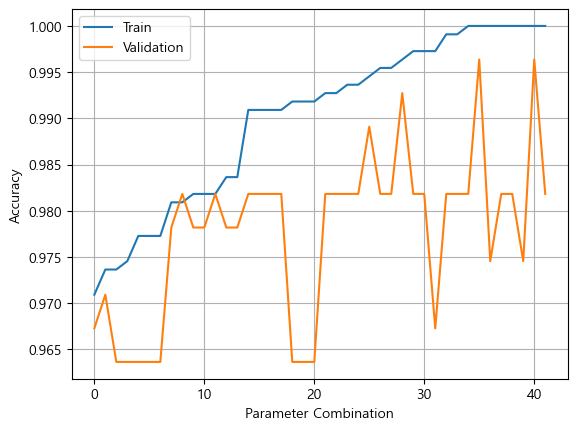

In [158]:
sns.lineplot(data=summary, x='index', y='mean_train_score', label='Train')
sns.lineplot(data=summary, x='index', y='mean_test_score', label='Validation')

plt.xlabel('Parameter Combination')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [154]:
results = pd.DataFrame(grid.cv_results_)

results['gap'] = (
    results['mean_train_score'] -
    results['mean_test_score']
)

display(
    results[
        ['params', 'mean_train_score',
         'mean_test_score', 'std_test_score', 'gap']
    ].sort_values(
        ['mean_test_score', 'gap'],
        ascending=[False, True]
    ).head(10)
)

,params,mean_train_score,mean_test_score,std_test_score,gap
4,"{'model': LogisticRegression(max_iter=5000, ra...",1.000000,0.996364,0.007273,0.003636
5,"{'model': LogisticRegression(max_iter=5000, ra...",1.000000,0.996364,0.007273,0.003636
2,"{'model': LogisticRegression(max_iter=5000, ra...",0.996364,0.992727,0.008907,0.003636
3,"{'model': LogisticRegression(max_iter=5000, ra...",0.994545,0.989091,0.014545,0.005455
18,{'model': RandomForestClassifier(random_state=...,0.980909,0.981818,0.019917,-0.000909
1,"{'model': LogisticRegression(max_iter=5000, ra...",0.981818,0.981818,0.019917,0.000000
28,{'model': RandomForestClassifier(random_state=...,0.990909,0.981818,0.019917,0.009091
29,{'model': RandomForestClassifier(random_state=...,0.990909,0.981818,0.019917,0.009091
34,{'model': RandomForestClassifier(random_state=...,0.990909,0.981818,0.019917,0.009091
40,{'model': RandomForestClassifier(random_state=...,0.990909,0.981818,0.019917,0.009091


In [159]:
best_model = grid.best_estimator_

print(grid.best_params_)
print(f"CV Accuracy: {grid.best_score_:.3%}")
print(f"Test Accuracy: {best_model.score(X_test, y_test):.3%}")

{'model': LogisticRegression(max_iter=5000, random_state=42, solver='saga'), 'model__C': 10, 'model__penalty': 'l1'}
CV Accuracy: 99.636%
Test Accuracy: 98.551%


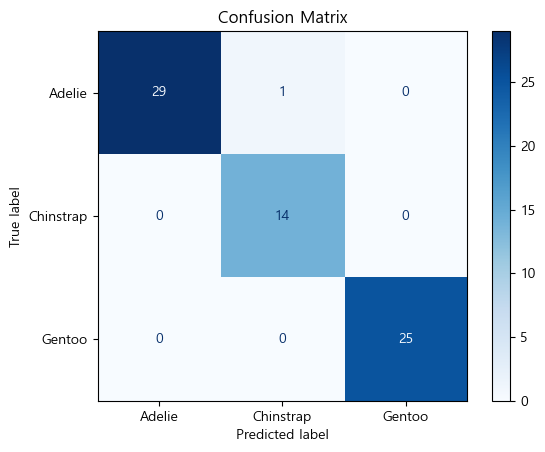

In [160]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# 예측
y_pred = grid.predict(X_test)

# 혼동행렬
cm = confusion_matrix(y_test, y_pred)

# 시각화
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=grid.classes_
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix')
plt.show()